# Telecom Billing Analysis: Exploratory Data Analysis

### 1) Problem statement
This analysis looks at how customers' monthly bills are driven by plan tier, data and call usage, overage charges, international (ISD) usage, tenure, and time. The goal is to find out what drives bill size, whether customers are on the right plan, and what the business could act on.

### 2) Data
- **Source file:** `telecom_billing_dataset_1500-v3.csv`
- **Structure:** 1,500 rows x 15 columns. Each row is one customer's bill for one month.
- **Panel:** 125 customers, each with 12 monthly bills (Nov 2025 to Oct 2026).
- **Currency:** not stated in the file. Amounts are shown as plain numbers.

**Column notes**
- `voice mails(mins)` is renamed `call_mins_used`. The name in the file is misleading. Section 3.6 verifies that it is the minutes of calls used, since the overage columns are calculated from it.
- `Extra data` and `Extra Call min` are overage amounts (usage above the plan quota).
- `ISD` = international (overseas) data and calls.

## 2.1 Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 2.2 Load the data and standardise column names

In [2]:
DATA_PATH = 'telecom_billing_dataset_1500-v3.csv'

RENAME = {
    'Customer_id': 'customer_id', 'Billing Date': 'billing_date',
    'Customer Tenure months': 'tenure_months', 'Plan tier': 'plan_tier',
    'Monthly rental': 'monthly_rental', 'plan data quota': 'data_quota',
    'plan call quota': 'call_quota', 'total data used(GB)': 'data_used_gb',
    'voice mails(mins)': 'call_mins_used', 'sms count': 'sms_count',
    'ISD Data used(GB)': 'isd_data_gb', 'ISD Call used(min)': 'isd_call_min',
    'Extra data': 'extra_data_gb', 'Extra Call min': 'extra_call_min',
    'Current Bill Amount': 'bill_amount',
}

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()
df = df.rename(columns=RENAME)
df['billing_date'] = pd.to_datetime(df['billing_date'])

print('Shape:', df.shape)
df.head()

Shape: (1500, 15)


,customer_id,billing_date,tenure_months,plan_tier,monthly_rental,data_quota,call_quota,data_used_gb,call_mins_used,sms_count,isd_data_gb,isd_call_min,extra_data_gb,extra_call_min,bill_amount
0,CUST_0001,2025-11-01,39,Gold_999,999,150,Unlimited,88.32,1742,52,0.00,0,0.00,0,"1,176.41"
1,CUST_0002,2025-11-01,5,Silver_599,599,75,2000,80.62,1762,71,0.00,0,5.62,0,815.27
2,CUST_0003,2025-11-01,25,Basic_399,399,40,1000,25.10,1088,39,0.00,0,0.00,88,527.56
3,CUST_0004,2025-11-01,7,Silver_599,599,75,2000,94.50,2129,92,0.00,0,19.50,129,"1,137.53"
4,CUST_0005,2025-11-01,33,Gold_999,999,150,Unlimited,136.40,1837,70,0.00,0,0.00,0,"1,176.39"


## 3. Data checks

### 3.1 Missing values

In [3]:
df.isna().sum()

customer_id       0
billing_date      0
tenure_months     0
plan_tier         0
monthly_rental    0
data_quota        0
call_quota        0
data_used_gb      0
call_mins_used    0
sms_count         0
isd_data_gb       0
isd_call_min      0
extra_data_gb     0
extra_call_min    0
bill_amount       0
dtype: int64

#### Insight
- No missing values in any column.

### 3.2 Duplicates

In [4]:
print('Fully duplicated rows:', df.duplicated().sum())
print('Duplicate (customer, month) pairs:', df.duplicated(['customer_id', 'billing_date']).sum())

Fully duplicated rows: 0
Duplicate (customer, month) pairs: 0


#### Insight
- No duplicate rows and no duplicate customer-month records. Repeated `customer_id` values are expected because each customer has 12 monthly bills.

### 3.3 Data types and unique values

In [5]:
df.dtypes.to_frame('dtype').join(df.nunique().to_frame('unique_values'))

,dtype,unique_values
customer_id,object,125
billing_date,datetime64[ns],12
tenure_months,int64,58
plan_tier,object,4
monthly_rental,int64,4
data_quota,object,4
call_quota,object,3
data_used_gb,float64,1433
call_mins_used,int64,1066
sms_count,int64,98


### 3.4 Panel structure: customers, months and tenure

In [6]:
print('Unique customers:', df.customer_id.nunique())
print('Bills per customer:', df.groupby('customer_id').size().value_counts().to_dict())
print('Billing period:', df.billing_date.min().date(), 'to', df.billing_date.max().date(),
      f'({df.billing_date.nunique()} months)')

# Tenure should rise by exactly 1 month for each subsequent bill
s = df.sort_values(['customer_id', 'billing_date'])
steps = s.groupby('customer_id').tenure_months.diff().dropna()
print('Share of consecutive bills where tenure rises by exactly 1 month: {:.1f}%'.format((steps == 1).mean() * 100))

Unique customers: 125
Bills per customer: {12: 125}
Billing period: 2025-11-01 to 2026-10-01 (12 months)
Share of consecutive bills where tenure rises by exactly 1 month: 100.0%


#### Insight
- The panel is complete: 125 customers x 12 months. Tenure increases by one month per bill, so the tenure field is internally consistent.

### 3.5 Plan specification consistency

Each plan tier should have one fixed rental price and one fixed set of quotas. The check below confirms this.

In [7]:
TIER_SPEC = {
    'Basic_399':     {'rental': 399,  'data_quota': 40,     'call_quota': 1000},
    'Silver_599':    {'rental': 599,  'data_quota': 75,     'call_quota': 2000},
    'Gold_999':      {'rental': 999,  'data_quota': 150,    'call_quota': np.inf},
    'Platinum_1499': {'rental': 1499, 'data_quota': np.inf, 'call_quota': np.inf},
}

rental_ok = df.monthly_rental.eq(df.plan_tier.map(lambda t: TIER_SPEC[t]['rental']))
print('Rows where rental matches tier price: {:.1f}%'.format(rental_ok.mean() * 100))

print('\nData quota label by tier:')
print(pd.crosstab(df.plan_tier, df.data_quota))
print('\nCall quota label by tier:')
print(pd.crosstab(df.plan_tier, df.call_quota))

Rows where rental matches tier price: 100.0%

Data quota label by tier:
data_quota     150   40   75  Unlimited
plan_tier                              
Basic_399        0  432    0          0
Gold_999       312    0    0          0
Platinum_1499    0    0    0        240
Silver_599       0    0  516          0

Call quota label by tier:
call_quota     1000  2000  Unlimited
plan_tier                           
Basic_399       432     0          0
Gold_999          0     0        312
Platinum_1499     0     0        240
Silver_599        0   516          0


#### Insight
- Every tier has a fixed price and fixed quotas, so the tier fully determines the plan. Platinum has unlimited data and calls, and Gold has unlimited calls.

### 3.6 Verify the overage columns

If `Extra data` and `Extra Call min` are overage amounts, they should equal usage minus quota (floored at zero). Checking this also confirms that `call_mins_used` is call usage.

In [8]:
exp_extra_gb = (df.data_used_gb - df.plan_tier.map(lambda t: TIER_SPEC[t]['data_quota'])).clip(lower=0)
exp_extra_min = (df.call_mins_used - df.plan_tier.map(lambda t: TIER_SPEC[t]['call_quota'])).clip(lower=0)

print('Extra data = max(0, used - quota):   {:.1f}% of rows match'.format(
    np.isclose(exp_extra_gb, df.extra_data_gb, atol=0.01).mean() * 100))
print('Extra calls = max(0, used - quota):  {:.1f}% of rows match'.format(
    np.isclose(exp_extra_min, df.extra_call_min, atol=0.5).mean() * 100))

Extra data = max(0, used - quota):   100.0% of rows match
Extra calls = max(0, used - quota):  100.0% of rows match


#### Insight
- Both overage columns match the formula exactly, so the overage fields are reliable. `call_mins_used` is the call-minutes field, despite its name.

### 3.7 Descriptive statistics

In [9]:
num_cols = ['tenure_months', 'monthly_rental', 'data_used_gb', 'call_mins_used', 'sms_count',
            'isd_data_gb', 'isd_call_min', 'extra_data_gb', 'extra_call_min', 'bill_amount']
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,"1,500.00",31.43,13.42,1.00,20.00,33.00,42.00,58.00
monthly_rental,"1,500.00",768.60,381.75,399.00,399.00,599.00,999.00,"1,499.00"
data_used_gb,"1,500.00",94.93,64.40,10.84,43.12,74.75,135.50,348.37
call_mins_used,"1,500.00","1,416.61",632.77,72.00,951.75,"1,315.00","1,797.75","3,809.00"
sms_count,"1,500.00",67.04,22.56,15.00,48.75,68.00,86.00,118.00
isd_data_gb,"1,500.00",0.05,0.36,0.00,0.00,0.00,0.00,6.31
isd_call_min,"1,500.00",1.13,6.99,0.00,0.00,0.00,0.00,100.00
extra_data_gb,"1,500.00",7.77,17.84,0.00,0.00,0.00,7.81,190.53
extra_call_min,"1,500.00",96.45,240.23,0.00,0.00,0.00,0.00,"1,809.00"
bill_amount,"1,500.00","1,132.65",584.97,458.20,703.66,"1,011.15","1,630.41","4,553.52"


#### Insight
- Average bill is about 1,133, with a wide range from roughly 458 to 4,554.
- ISD usage and overage are zero for most customers. The median of ISD data, ISD calls, extra data and extra calls is 0, so these are zero-inflated columns: most bills include no such charges.
- Data usage ranges from about 11 GB to 348 GB, while the plan quotas are 40 to unlimited GB, so usage varies a lot relative to the plan limits.

### 3.8 Categorical values

In [10]:
for c in ['plan_tier', 'data_quota', 'call_quota']:
    print(c, '->', df[c].unique().tolist())

plan_tier -> ['Gold_999', 'Silver_599', 'Basic_399', 'Platinum_1499']
data_quota -> ['150', '75', '40', 'Unlimited']
call_quota -> ['Unlimited', '2000', '1000']


## 4. Reconstructing the bill

A telecom bill should be explainable by the plan rental plus the charges for usage above quota and international usage. This section tests whether the bill can be rebuilt from its components.

### 4.1 Estimate the per-unit rates within each tier

For each tier, the bill minus rental is regressed on the four usage charges. The fitted coefficients show the unit rates. The fixed term (intercept) should match a flat tax on the rental.

In [11]:
rows = []
for tier, g in df.groupby('plan_tier'):
    X = np.column_stack([g.extra_data_gb, g.extra_call_min, g.isd_data_gb, g.isd_call_min,
                         np.ones(len(g))])
    y = g.bill_amount - g.monthly_rental
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    rows.append({'plan_tier': tier,
                 'per_extra_GB': b[0], 'per_extra_call_min': b[1],
                 'per_ISD_GB': b[2], 'per_ISD_call_min': b[3],
                 'fixed_term': b[4],
                 'fixed_term / rental': b[4] / g.monthly_rental.iloc[0]})
coef = pd.DataFrame(rows).set_index('plan_tier')
coef

,per_extra_GB,per_extra_call_min,per_ISD_GB,per_ISD_call_min,fixed_term,fixed_term / rental
plan_tier,,,,,,
Basic_399,17.71,0.59,293.74,14.26,72.11,0.18
Gold_999,17.70,-0.00,294.68,14.18,180.47,0.18
Platinum_1499,0.00,0.00,294.11,14.23,270.31,0.18
Silver_599,17.67,0.59,295.59,14.13,108.04,0.18


#### Insight
- The fixed term is about **18% of the rental** in every tier, which points to an 18% tax on the base plan.
- The per-GB and per-minute coefficients are about 1.18 times the underlying rates. Dividing by 1.18 gives the unit rates used below: **15 per extra GB, 0.50 per extra call minute, 250 per ISD GB, and 12 per ISD call minute**.
- Calls are unlimited on Gold and Platinum, so their extra-call coefficient is zero.

### 4.2 Test the reconstructed bill against the actual bill

In [12]:
RATES = {'extra_data': 15, 'extra_call': 0.5, 'isd_data': 250, 'isd_call': 12, 'tax': 0.18}

df['usage_charges'] = (RATES['extra_data'] * df.extra_data_gb
                       + RATES['extra_call'] * df.extra_call_min
                       + RATES['isd_data'] * df.isd_data_gb
                       + RATES['isd_call'] * df.isd_call_min)
df['expected_bill'] = (df.monthly_rental + df.usage_charges) * (1 + RATES['tax'])
df['bill_gap'] = df.bill_amount - df.expected_bill
pct_gap = df.bill_gap.abs() / df.bill_amount * 100

print('Mean absolute gap: {:.2f}%'.format(pct_gap.mean()))
print('Bills within 1% of the formula: {:.1f}%'.format((pct_gap <= 1).mean() * 100))
print('Std of the gap (currency units): {:.2f}'.format(df.bill_gap.std()))

Mean absolute gap: 0.49%
Bills within 1% of the formula: 87.2%
Std of the gap (currency units): 5.56


#### Insight
- The bill is reproduced to within 1% for 87% of rows, with a mean gap of 0.5%. The remaining gap is small random noise with no pattern by tier or tenure.
- This means the billing logic is consistent. Any unusual bill should be explained by usage, not by an unexplained charge.

### 4.3 Bill-gap check: is the residual structured?

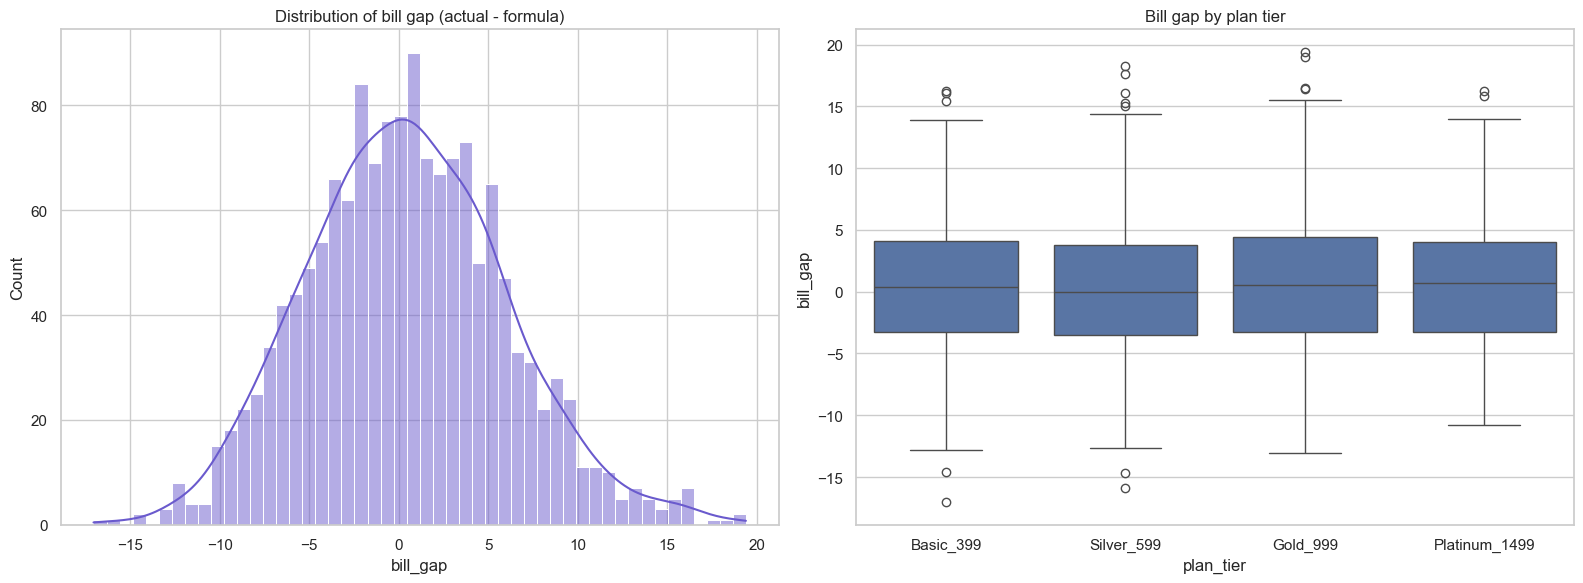

Gap correlation with tenure: 0.036


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.histplot(df.bill_gap, bins=50, kde=True, color='slateblue', ax=ax[0])
ax[0].set_title('Distribution of bill gap (actual - formula)')
sns.boxplot(x='plan_tier', y='bill_gap', data=df,
            order=['Basic_399', 'Silver_599', 'Gold_999', 'Platinum_1499'], ax=ax[1])
ax[1].set_title('Bill gap by plan tier')
plt.tight_layout(); plt.show()
print('Gap correlation with tenure:', round(df[['bill_gap', 'tenure_months']].corr().iloc[0, 1], 3))

#### Insight
- The gap centres on zero for every tier and does not correlate with tenure. It is treated as noise and does not change the conclusions.

## 5. Univariate analysis

### 5.1 Distribution of numeric features

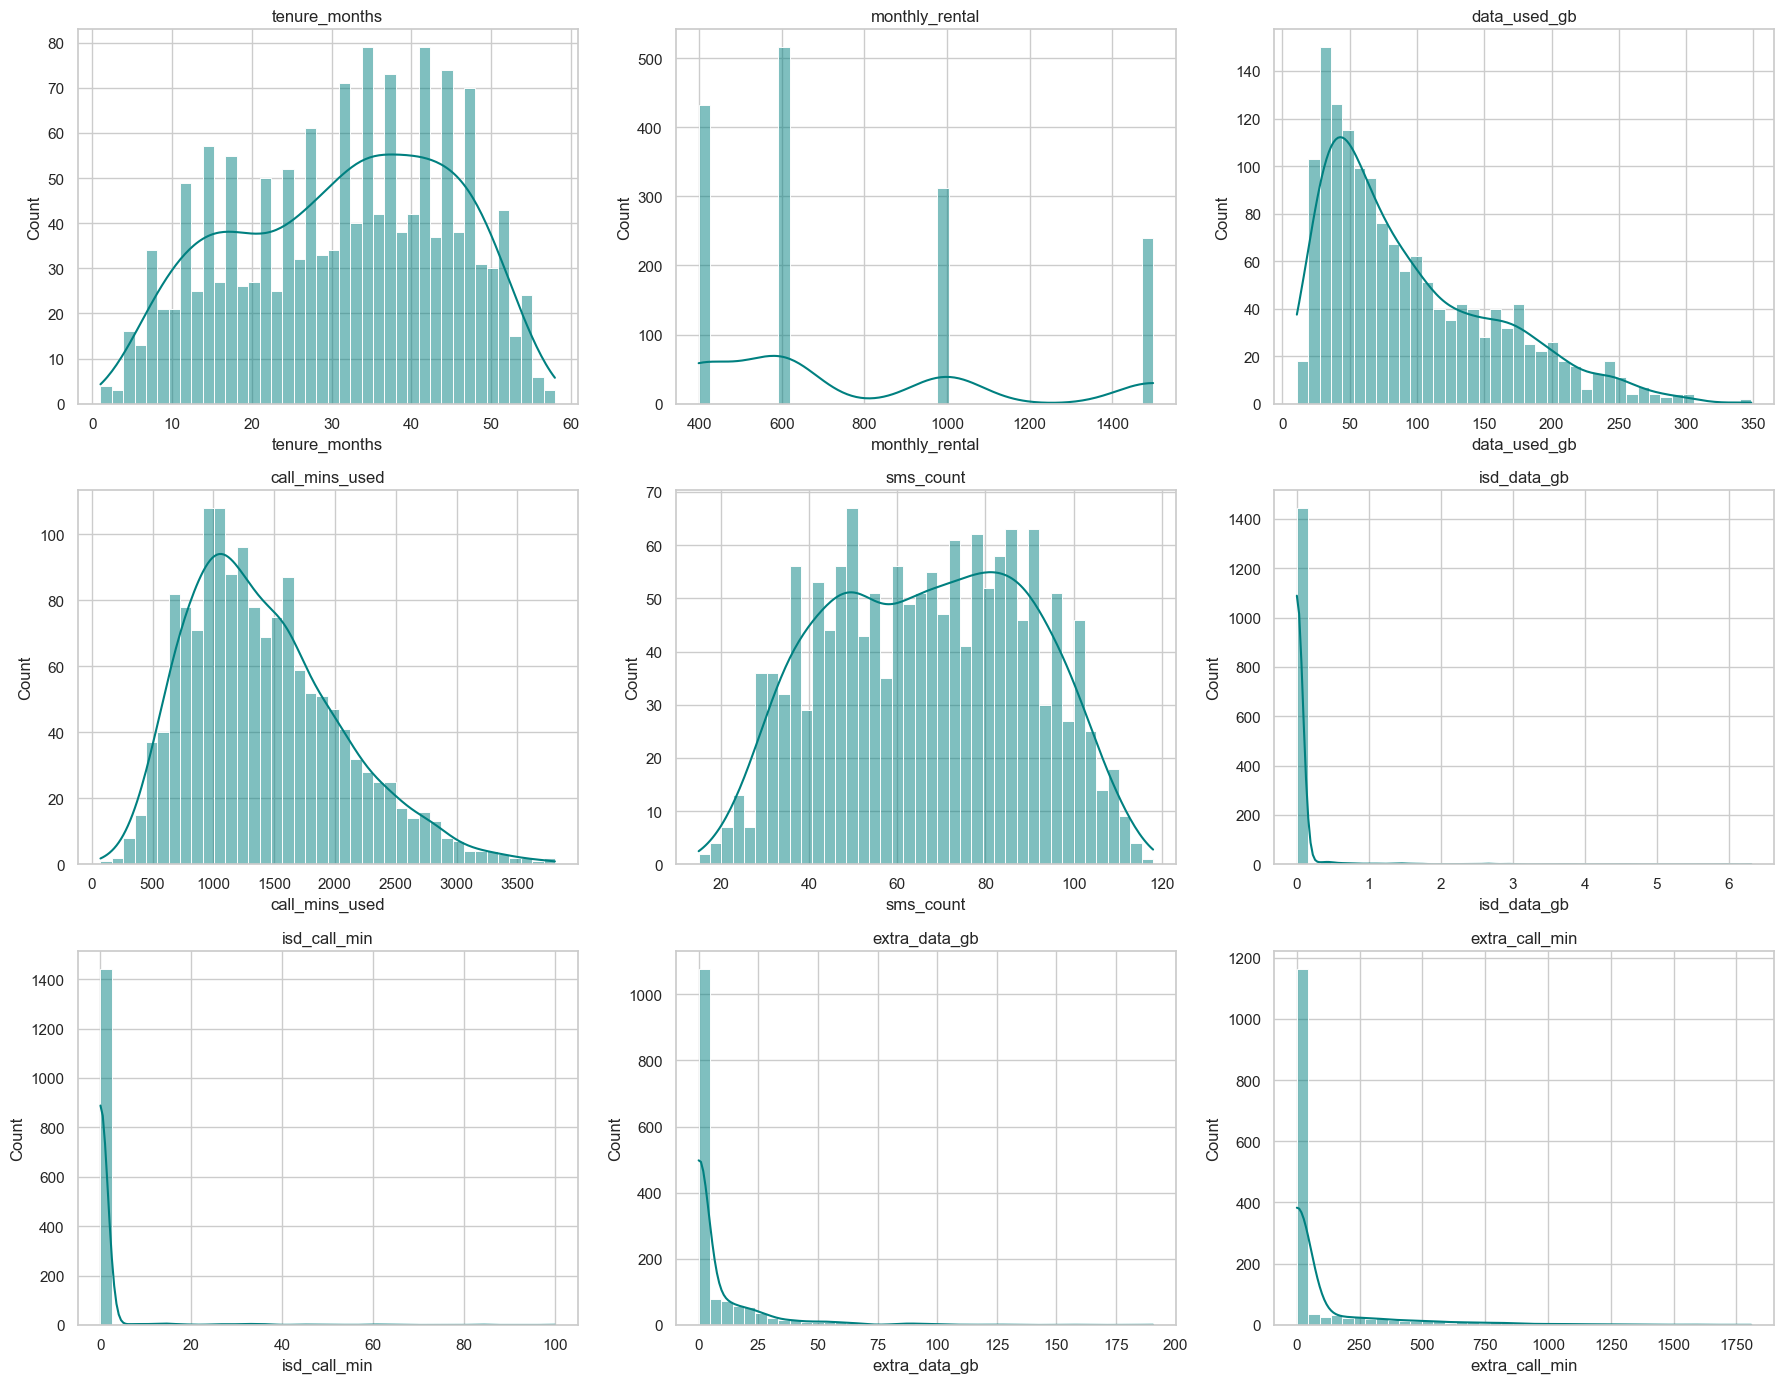

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
for ax, c in zip(axes.flat, num_cols):
    sns.histplot(df[c], bins=40, kde=True, color='teal', ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

#### Insight
- Tenure ranges from 1 to 58 months, with a median of 33.
- SMS count is roughly symmetric. Data usage and call minutes are right-skewed (data mean about 95 GB vs median about 75 GB), and bill amount is more strongly right-skewed: a small number of customers pay much more than the typical bill.
- ISD and overage variables have large spikes at zero, showing that these charges only apply to a subset of customers.

### 5.2 Plan tier distribution

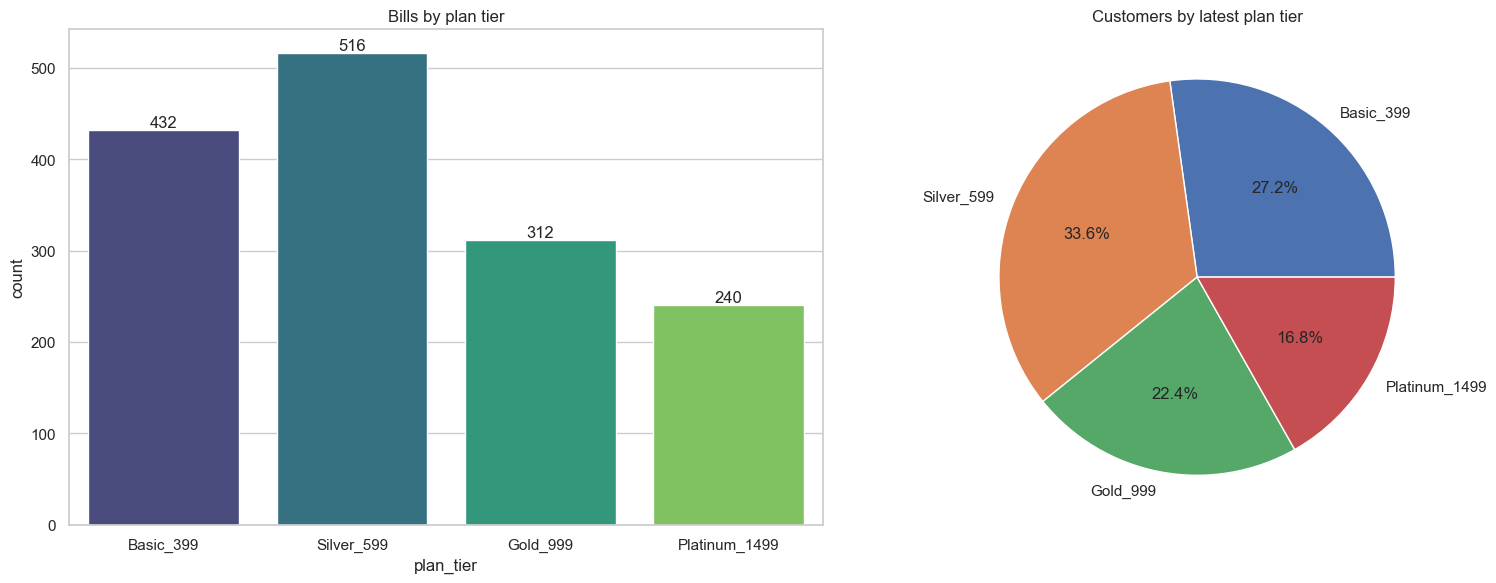

In [15]:
order = ['Basic_399', 'Silver_599', 'Gold_999', 'Platinum_1499']
df_sorted = df.sort_values(['customer_id', 'billing_date'])
latest_tier = df_sorted.groupby('customer_id').plan_tier.last()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.countplot(x='plan_tier', data=df, order=order, palette='viridis', ax=ax[0])
for c in ax[0].containers:
    ax[0].bar_label(c)
ax[0].set_title('Bills by plan tier')

latest_tier.value_counts().reindex(order).plot.pie(autopct='%1.1f%%', ax=ax[1], ylabel='')
ax[1].set_title('Customers by latest plan tier')
plt.tight_layout(); plt.show()

#### Insight
- Silver is the most common tier (about 34% of bills), followed by Basic (about 29%). Platinum is the least common.
- Customers are spread across tiers in a similar pattern to the bill counts.

### 5.3 Billing month distribution

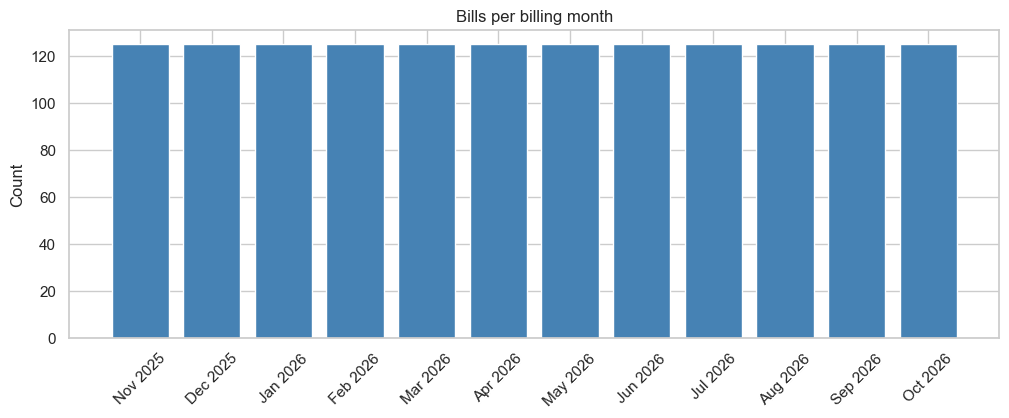

In [16]:
counts = df.billing_date.value_counts().sort_index()
plt.figure(figsize=(12, 4))
plt.bar(counts.index.strftime('%b %Y'), counts.values, color='steelblue')
plt.xticks(rotation=45)
plt.title('Bills per billing month'); plt.ylabel('Count'); plt.show()

#### Insight
- Every month has exactly 125 bills, one per customer, so the monthly panel is balanced.

## 6. Bivariate analysis

### 6.1 How plan tier relates to usage

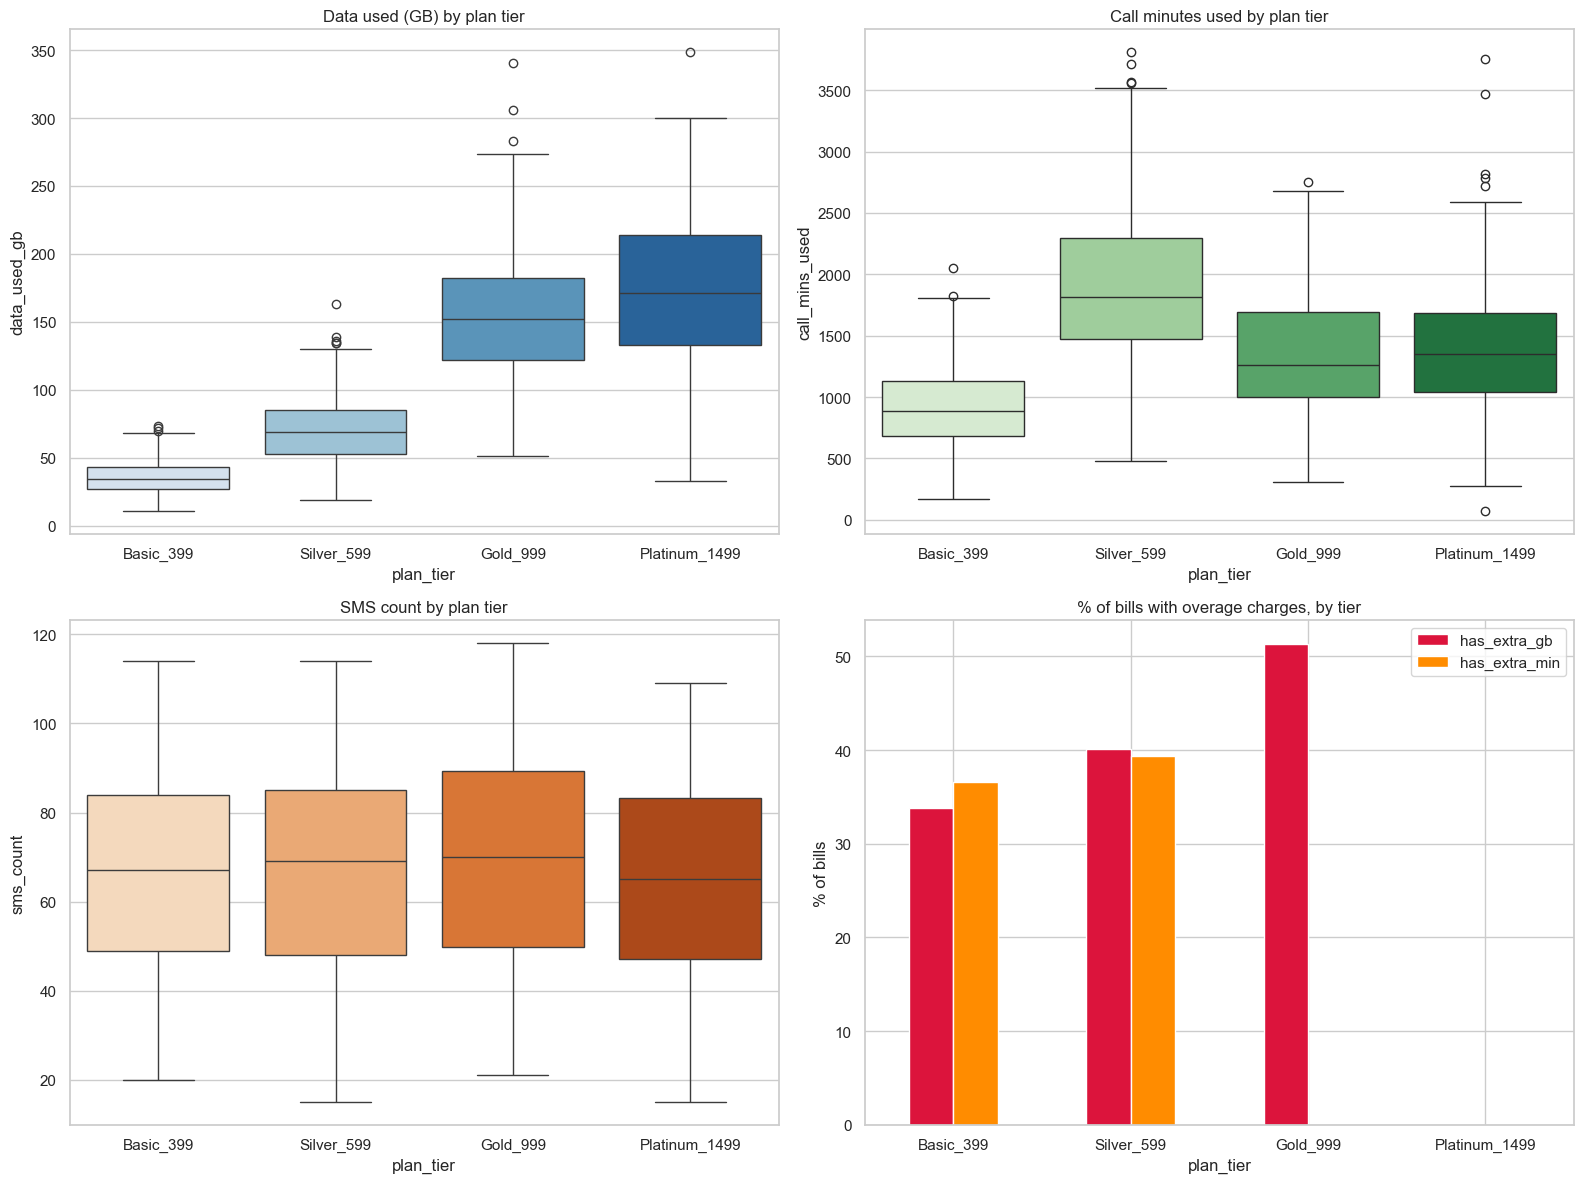

,has_extra_gb,has_extra_min
plan_tier,,
Basic_399,33.80,36.60
Silver_599,40.10,39.30
Gold_999,51.30,0.00
Platinum_1499,0.00,0.00


In [17]:
fig, ax = plt.subplots(2, 2, figsize=(16, 12))
sns.boxplot(x='plan_tier', y='data_used_gb', data=df, order=order, ax=ax[0, 0], palette='Blues')
ax[0, 0].set_title('Data used (GB) by plan tier')

sns.boxplot(x='plan_tier', y='call_mins_used', data=df, order=order, ax=ax[0, 1], palette='Greens')
ax[0, 1].set_title('Call minutes used by plan tier')

sns.boxplot(x='plan_tier', y='sms_count', data=df, order=order, ax=ax[1, 0], palette='Oranges')
ax[1, 0].set_title('SMS count by plan tier')

share_overage = df.assign(has_extra_gb=df.extra_data_gb > 0, has_extra_min=df.extra_call_min > 0) \
                  .groupby('plan_tier')[['has_extra_gb', 'has_extra_min']].mean().reindex(order) * 100
share_overage.plot(kind='bar', ax=ax[1, 1], color=['crimson', 'darkorange'])
ax[1, 1].set_title('% of bills with overage charges, by tier')
ax[1, 1].set_ylabel('% of bills'); ax[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout(); plt.show()
share_overage.round(1)

#### Insight
- Average usage scales with tier: about 36 GB on Basic, 71 GB on Silver, 154 GB on Gold and 176 GB on Platinum. Plans are sized to usage on average.
- Overage is still common. About 34% of Basic bills and 40% of Silver bills carry extra-data charges, and 51% of Gold bills do too, even though Gold has a 150 GB quota.
- Extra call charges only apply to Basic and Silver, since Gold and Platinum include unlimited calls. Platinum has unlimited data and calls, so it has no overage charges by design.

### 6.2 Bill composition by plan tier

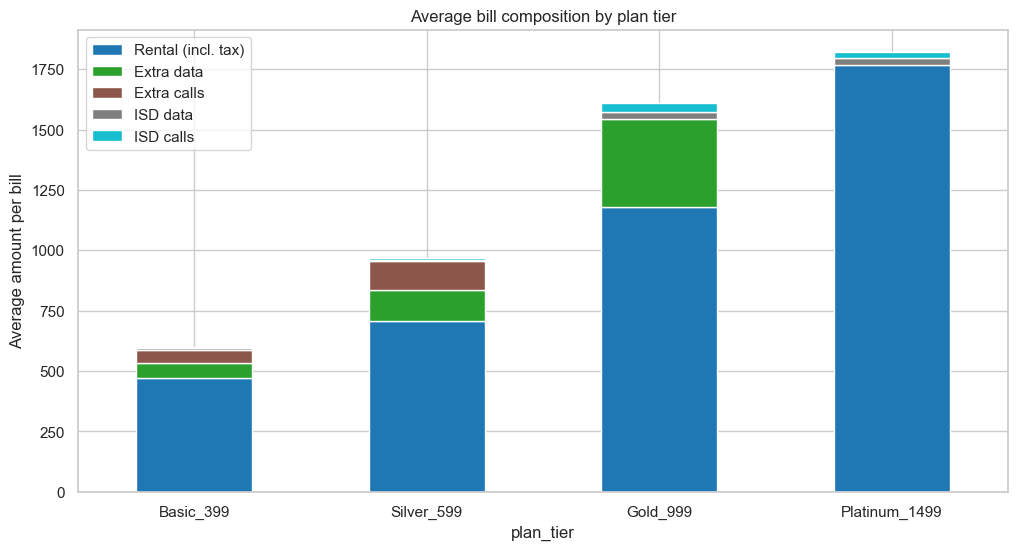

,Rental (incl. tax),Extra data,Extra calls,ISD data,ISD calls
plan_tier,,,,,
Basic_399,78.50,10.40,9.20,1.20,0.80
Silver_599,73.00,13.20,12.30,0.60,0.80
Gold_999,73.20,22.60,0.00,1.80,2.40
Platinum_1499,97.10,0.00,0.00,1.60,1.30


In [18]:
comp = pd.DataFrame({
    'Rental (incl. tax)': df.monthly_rental * (1 + RATES['tax']),
    'Extra data': RATES['extra_data'] * (1 + RATES['tax']) * df.extra_data_gb,
    'Extra calls': RATES['extra_call'] * (1 + RATES['tax']) * df.extra_call_min,
    'ISD data': RATES['isd_data'] * (1 + RATES['tax']) * df.isd_data_gb,
    'ISD calls': RATES['isd_call'] * (1 + RATES['tax']) * df.isd_call_min,
    'plan_tier': df.plan_tier,
})
share = comp.groupby('plan_tier').mean().reindex(order)

ax = share.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab10')
ax.set_title('Average bill composition by plan tier')
ax.set_ylabel('Average amount per bill'); ax.tick_params(axis='x', rotation=0)
plt.show()

pct = share.div(share.sum(axis=1), axis=0) * 100
pct.round(1)

#### Insight
- Rental is about 73 to 78% of the average bill on Basic, Silver and Gold, and about 97% on Platinum, which has no overage.
- Overage (extra data and extra calls) is about 20 to 26% of the average bill on Basic, Silver and Gold.
- International (ISD) charges are small, about 1 to 4% of the average bill, and appear in only about 4.5% of bills.

### 6.3 Bill amount by plan tier

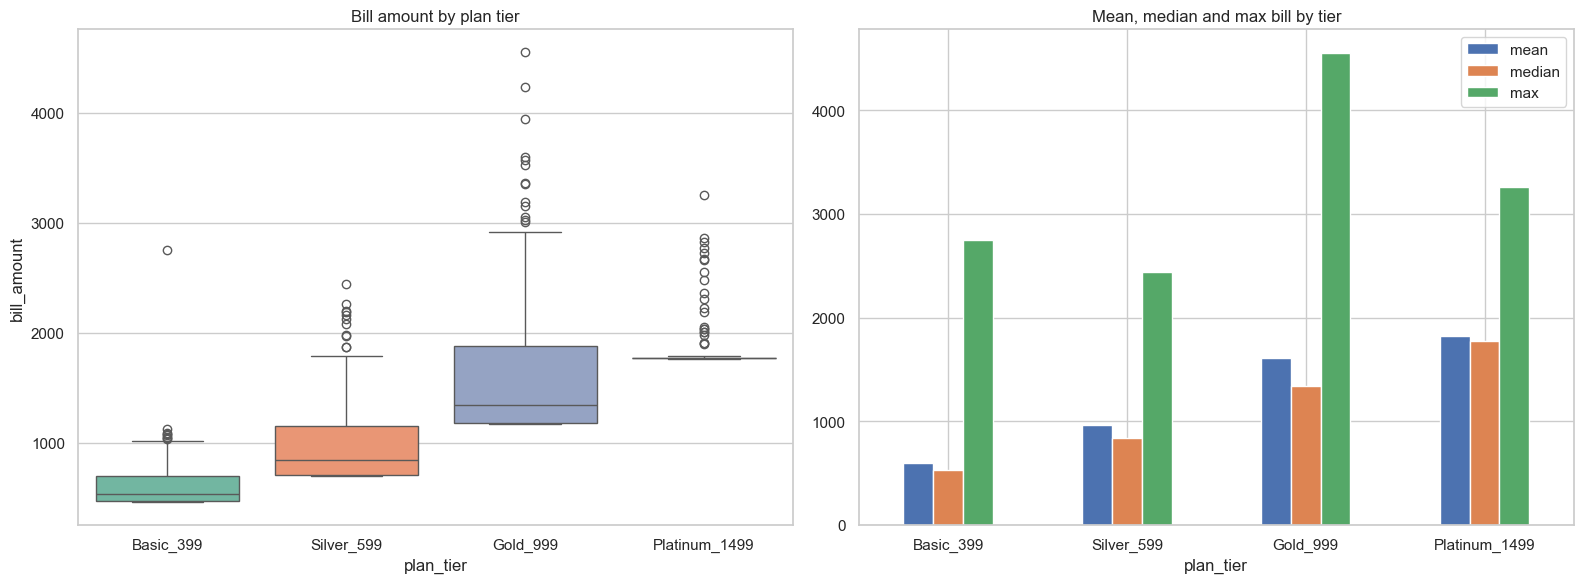

,mean,median,std,max
plan_tier,,,,
Basic_399,600.40,529.60,182.50,"2,750.90"
Silver_599,968.20,839.90,323.70,"2,439.60"
Gold_999,"1,610.80","1,338.70",602.30,"4,553.50"
Platinum_1499,"1,822.50","1,770.10",204.10,"3,256.50"


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(x='plan_tier', y='bill_amount', data=df, order=order, palette='Set2', ax=ax[0])
ax[0].set_title('Bill amount by plan tier')
df.groupby('plan_tier').bill_amount.agg(['mean', 'median', 'max']).reindex(order) \
  .plot(kind='bar', ax=ax[1], rot=0)
ax[1].set_title('Mean, median and max bill by tier')
plt.tight_layout(); plt.show()

df.groupby('plan_tier').bill_amount.agg(['mean', 'median', 'std', 'max']).reindex(order).round(1)

#### Insight
- Average bills rise with tier, from about 600 on Basic to about 1,820 on Platinum.
- The largest bills are on Gold: its maximum (about 4,554) is 3.4 times its median. Basic's maximum is about 5 times its median, so overage can push bills far above the plan price on cheaper plans too.
- Platinum bills are the most stable, which is expected from a flat-price unlimited plan.

### 6.4 Usage by tenure

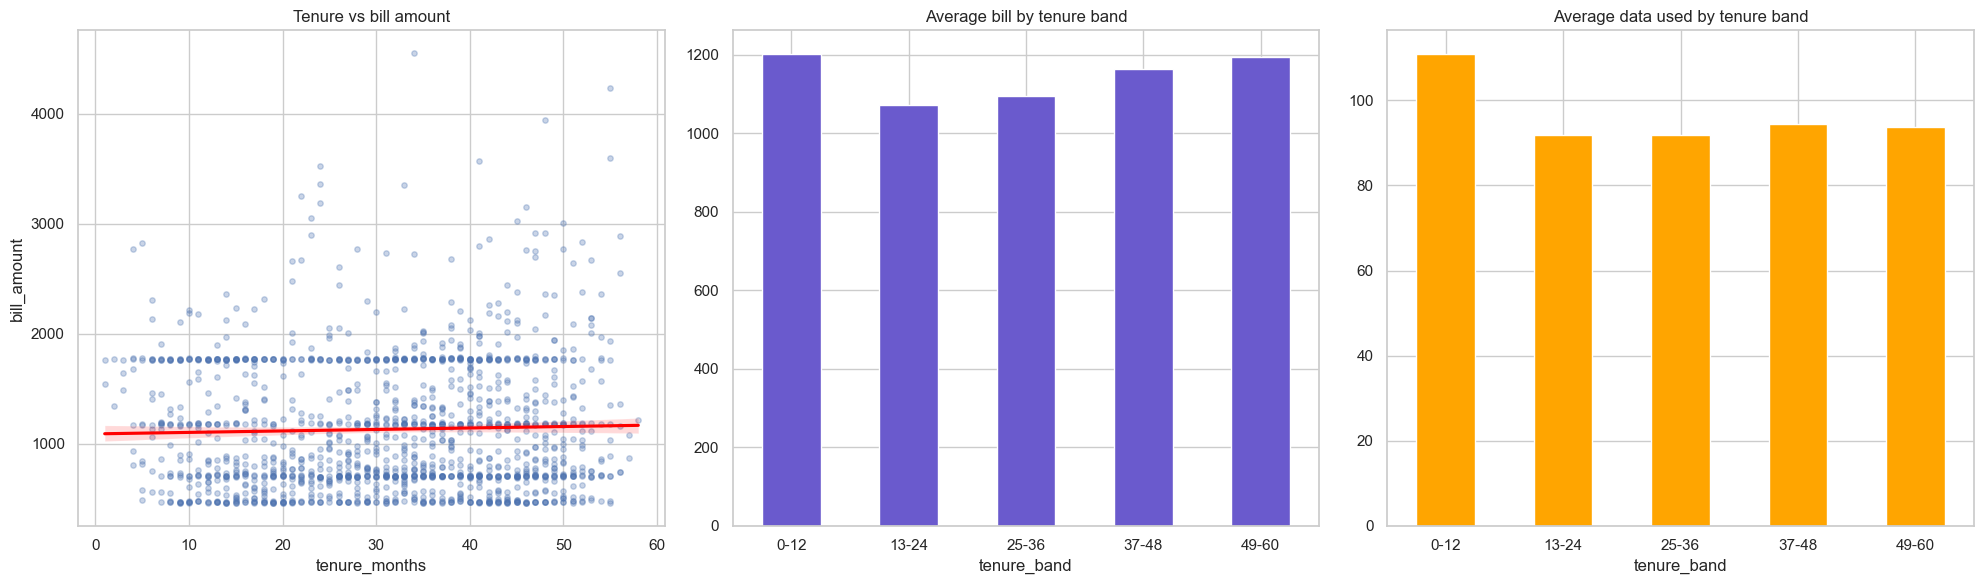

Correlation, tenure vs bill: 0.031
Correlation, tenure vs data used: -0.044


In [20]:
df['tenure_band'] = pd.cut(df.tenure_months, bins=[0, 12, 24, 36, 48, 60],
                           labels=['0-12', '13-24', '25-36', '37-48', '49-60'])

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
sns.regplot(x='tenure_months', y='bill_amount', data=df, scatter_kws={'alpha': 0.3, 's': 15},
            line_kws={'color': 'red'}, ax=ax[0])
ax[0].set_title('Tenure vs bill amount')

df.groupby('tenure_band', observed=True).bill_amount.mean().plot.bar(ax=ax[1], color='slateblue', rot=0)
ax[1].set_title('Average bill by tenure band')

df.groupby('tenure_band', observed=True).data_used_gb.mean().plot.bar(ax=ax[2], color='orange', rot=0)
ax[2].set_title('Average data used by tenure band')
plt.tight_layout(); plt.show()

print('Correlation, tenure vs bill:', round(df[['tenure_months', 'bill_amount']].corr().iloc[0, 1], 3))
print('Correlation, tenure vs data used:', round(df[['tenure_months', 'data_used_gb']].corr().iloc[0, 1], 3))

#### Insight
- Tenure has little relationship with bill size or usage (correlations near zero). Long-standing customers are not paying more or using more than new ones.
- Tenure is therefore not a useful predictor of bill size in this data.

## 7. Time trends

### 7.1 Average metrics per billing month

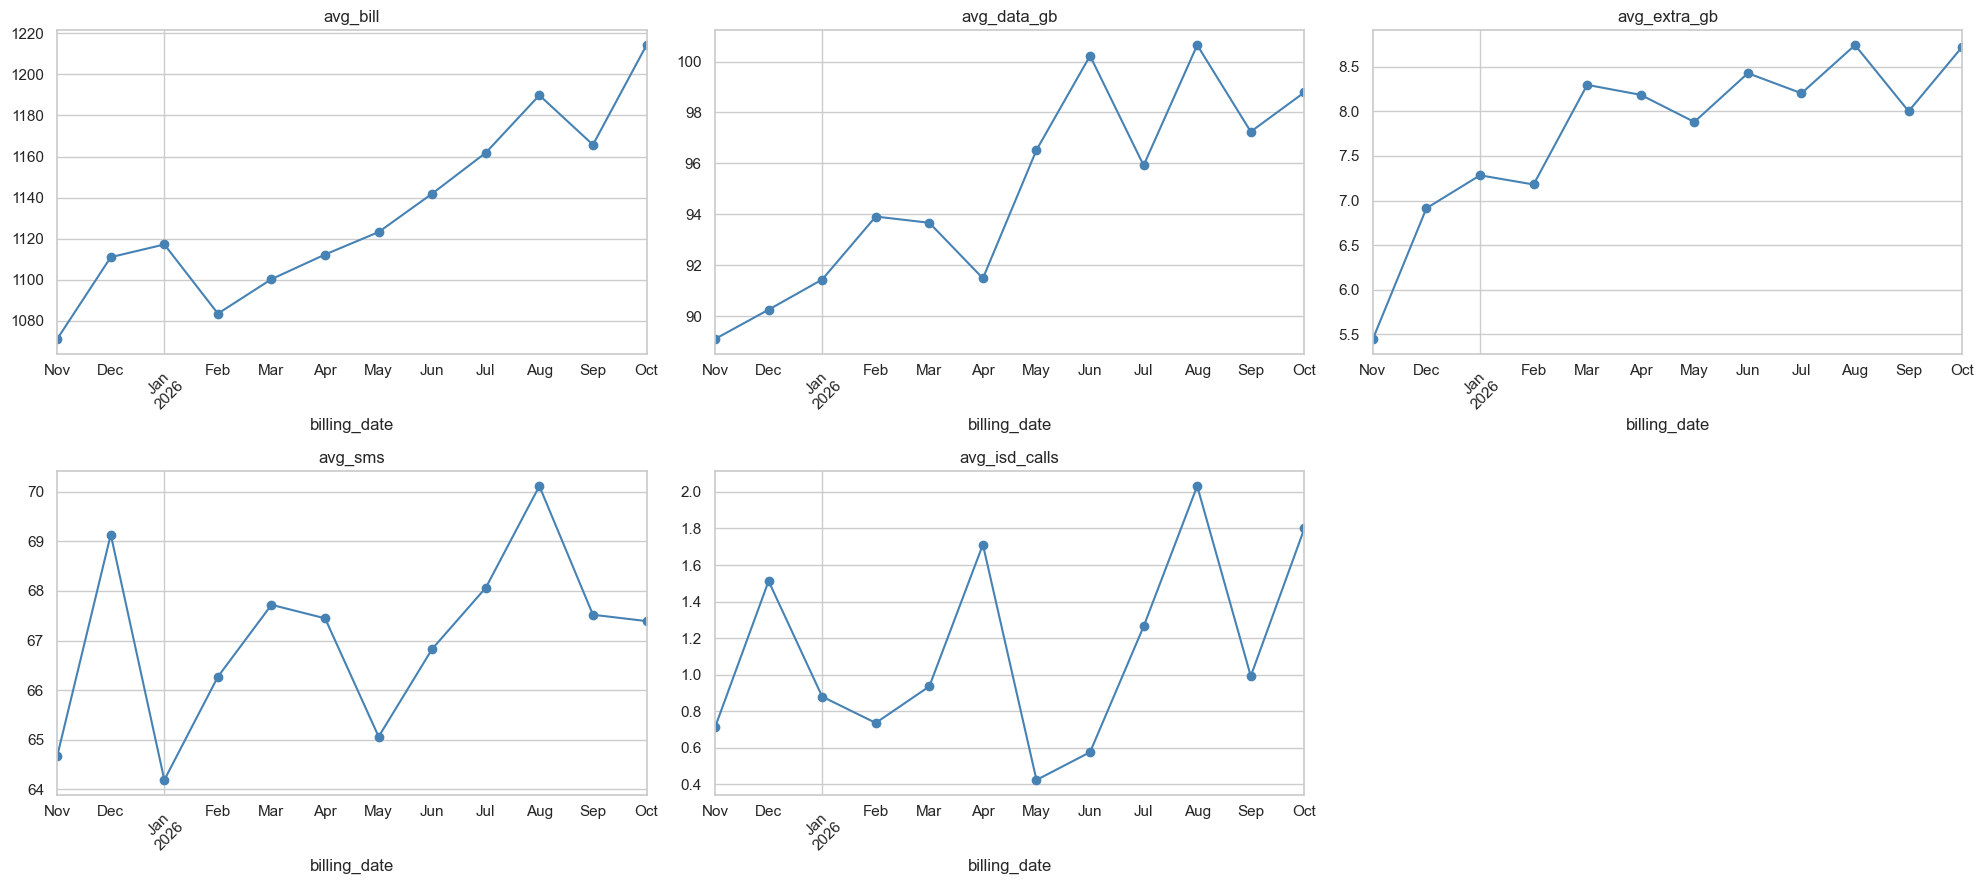

,avg_bill,avg_data_gb,avg_extra_gb,avg_sms,avg_isd_calls
billing_date,,,,,
2025-11-01,"1,071.10",89.10,5.40,64.70,0.70
2025-12-01,"1,110.90",90.30,6.90,69.10,1.50
2026-01-01,"1,117.10",91.40,7.30,64.20,0.90
2026-02-01,"1,083.40",93.90,7.20,66.30,0.70
2026-03-01,"1,100.20",93.70,8.30,67.70,0.90
2026-04-01,"1,112.20",91.50,8.20,67.40,1.70
2026-05-01,"1,123.20",96.50,7.90,65.10,0.40
2026-06-01,"1,141.90",100.20,8.40,66.80,0.60
2026-07-01,"1,161.80",95.90,8.20,68.10,1.30


In [21]:
monthly = df.groupby('billing_date').agg(
    avg_bill=('bill_amount', 'mean'),
    avg_data_gb=('data_used_gb', 'mean'),
    avg_extra_gb=('extra_data_gb', 'mean'),
    avg_sms=('sms_count', 'mean'),
    avg_isd_calls=('isd_call_min', 'mean'),
)

fig, ax = plt.subplots(2, 3, figsize=(20, 9))
for a, c in zip(ax.flat, monthly.columns):
    monthly[c].plot(ax=a, marker='o', color='steelblue')
    a.set_title(c); a.tick_params(axis='x', rotation=45)
ax.flat[-1].axis('off')
plt.tight_layout(); plt.show()

monthly.round(1)

In [22]:
first, last = monthly.iloc[0], monthly.iloc[-1]
change = ((last / first - 1) * 100).round(1)
print('Change from first month (Nov 2025) to last month (Oct 2026), %:')
print(change)

Change from first month (Nov 2025) to last month (Oct 2026), %:
avg_bill         13.40
avg_data_gb      10.90
avg_extra_gb     60.10
avg_sms           4.20
avg_isd_calls   152.80
dtype: float64


#### Insight
- Average bill rose from about 1,071 to about 1,214 over the year, roughly 13% higher.
- Average data usage grew about 11%, from about 89 GB to about 99 GB, and average extra-data charges rose about 60%. Rental prices are fixed in the data, so the increase comes from usage.
- SMS volume is broadly flat (up about 4%). ISD calls rose sharply from a very small base but remain too few to move the total bill.

## 8. Customer-level analysis

### 8.1 Customers who changed plan tier

In [23]:
rank = {'Basic_399': 1, 'Silver_599': 2, 'Gold_999': 3, 'Platinum_1499': 4}

path = df_sorted.groupby('customer_id').plan_tier.agg(lambda s: ' -> '.join(dict.fromkeys(s)))
switchers = path[path.str.contains('->')]
print('Customers who changed tier during the year:', len(switchers), 'of', df.customer_id.nunique())
print(switchers.value_counts().to_string())

first = df_sorted.groupby('customer_id').plan_tier.first().map(rank)
last = df_sorted.groupby('customer_id').plan_tier.last().map(rank)
move = last - first
print('\nUpgrades:', int((move > 0).sum()), '| Downgrades:', int((move < 0).sum()))

Customers who changed tier during the year: 12 of 125
plan_tier
Silver_599 -> Gold_999       6
Basic_399 -> Silver_599      4
Gold_999 -> Platinum_1499    2

Upgrades: 12 | Downgrades: 0


#### Insight
- Twelve customers changed plan during the year, and all 12 moves were upgrades (no downgrades): six Silver to Gold, four Basic to Silver and two Gold to Platinum.
- Tier changes are rare. Most customers stay on one plan for all 12 months, and no customer moved down, even though many would have paid less on a lower tier.

### 8.2 Customer summary

In [24]:
cust = df.groupby('customer_id').agg(
    avg_bill=('bill_amount', 'mean'),
    avg_data_gb=('data_used_gb', 'mean'),
    avg_extra_gb=('extra_data_gb', 'mean'),
    total_billed=('bill_amount', 'sum'),
)
cust.describe().round(1)

,avg_bill,avg_data_gb,avg_extra_gb,total_billed
count,125.00,125.00,125.00,125.00
mean,"1,132.70",94.90,7.80,"13,591.80"
std,505.70,59.50,12.50,"6,068.00"
min,469.30,24.10,0.00,"5,631.30"
25%,683.20,45.10,0.00,"8,198.30"
50%,991.90,76.00,2.30,"11,903.00"
75%,"1,624.40",139.00,9.70,"19,493.20"
max,"2,510.10",250.30,61.80,"30,121.00"


#### Insight
- Average bill per customer varies widely, from about 470 to about 2,510. The highest-spending customers combine high data use with large overage charges.

## 9. Plan fit: would a different tier be cheaper?

For each bill, the cost is calculated under all four tiers using the same usage. This shows whether the customer's current tier is the cheapest for that month's usage. The analysis covers cost only. It does not include the value of unlimited plans or the risk of a customer leaving.

In [25]:
costs = {}
for tier, spec in TIER_SPEC.items():
    extra_gb = (df.data_used_gb - spec['data_quota']).clip(lower=0)
    extra_min = (df.call_mins_used - spec['call_quota']).clip(lower=0)
    costs[tier] = (spec['rental'] + RATES['extra_data'] * extra_gb + RATES['extra_call'] * extra_min
                   + RATES['isd_data'] * df.isd_data_gb + RATES['isd_call'] * df.isd_call_min) \
                  * (1 + RATES['tax'])
costs = pd.DataFrame(costs)

col_idx = df.plan_tier.map({t: i for i, t in enumerate(costs.columns)}).values
df['cost_current_plan'] = costs.values[np.arange(len(df)), col_idx]
df['cost_cheapest'] = costs.min(axis=1)
df['cheapest_tier'] = costs.idxmin(axis=1)
df['potential_saving'] = df.cost_current_plan - df.cost_cheapest

print('Bills where another tier would be cheaper: {:.1f}%'.format((df.potential_saving > 0.5).mean() * 100))
print('Total potential saving across all bills: {:,.0f}'.format(df.potential_saving.sum()))
print('Total billed under current plans (formula): {:,.0f}'.format(df.cost_current_plan.sum()))

Bills where another tier would be cheaper: 32.2%
Total potential saving across all bills: 164,788
Total billed under current plans (formula): 1,698,307


In [26]:
pd.crosstab(df.plan_tier, df.cheapest_tier, normalize='index').reindex(order).round(3) * 100

cheapest_tier,Basic_399,Gold_999,Platinum_1499,Silver_599
plan_tier,,,,
Basic_399,79.20,0.00,0.00,20.80
Silver_599,4.50,21.70,0.00,73.80
Gold_999,0.00,63.80,24.70,11.50
Platinum_1499,0.00,55.00,39.60,5.40


In [27]:
df.groupby('plan_tier').potential_saving.agg(['mean', 'sum']).reindex(order).round(1)

,mean,sum
plan_tier,,
Basic_399,24.90,"10,738.60"
Silver_599,58.00,"29,914.30"
Gold_999,171.20,"53,426.00"
Platinum_1499,294.60,"70,709.00"


#### Insight
- About 32% of bills would be cheaper on a different tier for the same usage.
- The largest gap is on Platinum. Platinum is the cheapest tier in only about 40% of its bills, and Gold is cheaper in about 55%. Platinum only beats Gold once usage passes roughly 183 GB, and median Platinum usage is about 171 GB.
- On Gold, about 25% of bills would be cheaper on Platinum. These are heavy data users, above roughly 183 GB, whose overage exceeds the Platinum premium. On Silver, about 22% would be cheaper on Gold, and on Basic about 21% would be cheaper on Silver.
- Potential savings total about 165,000, about 10% of the billed amount. Platinum customers account for the largest share, about 71,000.
- These figures are cost-only. Customers may value unlimited plans for reasons beyond cost, so treat them as a starting point.

## 10. Outliers

### 10.1 IQR-based outlier counts
Columns where most values are zero have an IQR of zero, so the IQR rule flags every non-zero value. These columns are marked separately.

In [28]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    if iqr == 0:
        return np.nan
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

out = pd.Series({c: iqr_outliers(df[c]) for c in num_cols}, name='iqr_outliers')
out.to_frame().assign(pct=lambda d: (d.iqr_outliers / len(df) * 100).round(1))

,iqr_outliers,pct
tenure_months,0.00,0.00
monthly_rental,0.00,0.00
data_used_gb,13.00,0.90
call_mins_used,22.00,1.50
sms_count,0.00,0.00
isd_data_gb,NaN,NaN
isd_call_min,NaN,NaN
extra_data_gb,211.00,14.10
extra_call_min,NaN,NaN
bill_amount,13.00,0.90


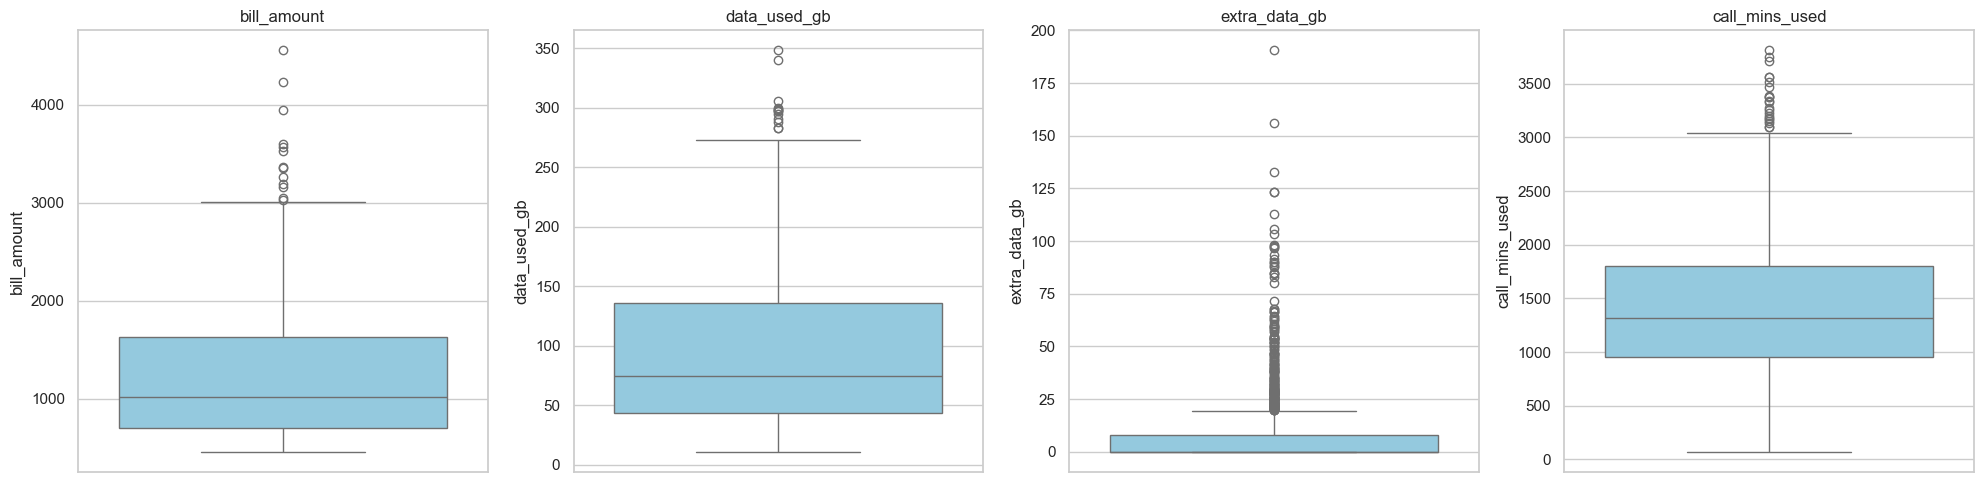

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, c in zip(axes, ['bill_amount', 'data_used_gb', 'extra_data_gb', 'call_mins_used']):
    sns.boxplot(y=df[c], color='skyblue', ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

In [30]:
df.nlargest(8, 'bill_amount')[['customer_id', 'billing_date', 'plan_tier', 'data_used_gb',
                               'extra_data_gb', 'extra_call_min', 'bill_amount']]

,customer_id,billing_date,plan_tier,data_used_gb,extra_data_gb,extra_call_min,bill_amount
621,CUST_0122,2026-03-01,Gold_999,340.53,190.53,0,"4,553.52"
1435,CUST_0061,2026-10-01,Gold_999,96.51,0.00,0,"4,234.73"
570,CUST_0071,2026-03-01,Gold_999,306.17,156.17,0,"3,941.46"
1295,CUST_0046,2026-09-01,Gold_999,196.31,46.31,0,"3,600.40"
657,CUST_0033,2026-04-01,Gold_999,195.31,45.31,0,"3,566.74"
1050,CUST_0051,2026-07-01,Gold_999,282.80,132.80,0,"3,526.41"
1244,CUST_0120,2026-08-01,Gold_999,273.22,123.22,0,"3,360.50"
496,CUST_0122,2026-02-01,Gold_999,273.15,123.15,0,"3,352.13"


#### Insight
- The high bills are not data errors. The 8 largest bills are all on the Gold plan. Seven come from data overage at 195 to 340 GB of usage. One (CUST_0061, October 2026) comes from international usage: 6.3 GB of ISD data and 84 ISD minutes add about 3,050 on top of the rental.
- Outliers should be investigated as account-level cases, such as heavy-usage or heavy-international accounts, rather than removed.

## 11. Multivariate analysis

### 11.1 Correlation matrix

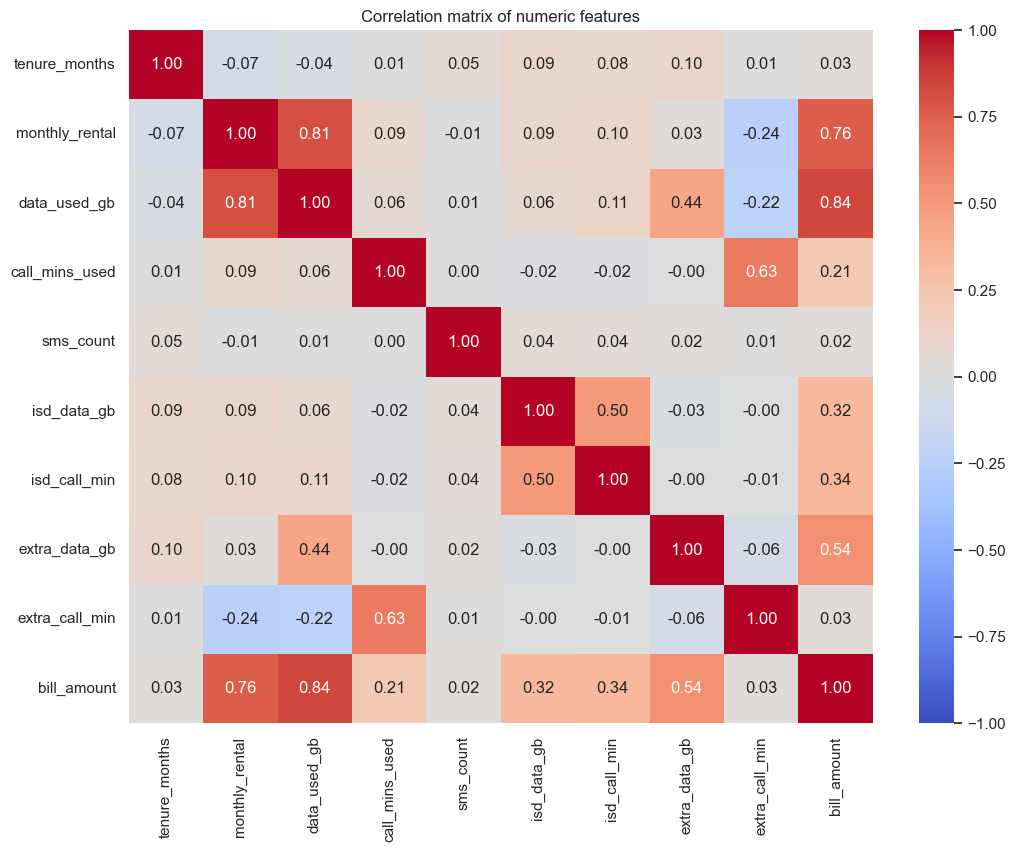

data_used_gb     0.84
monthly_rental   0.76
extra_data_gb    0.54
isd_call_min     0.34
isd_data_gb      0.32
call_mins_used   0.21
tenure_months    0.03
extra_call_min   0.03
sms_count        0.02
Name: bill_amount, dtype: float64

In [31]:
corr_cols = ['tenure_months', 'monthly_rental', 'data_used_gb', 'call_mins_used', 'sms_count',
             'isd_data_gb', 'isd_call_min', 'extra_data_gb', 'extra_call_min', 'bill_amount']
corr = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix of numeric features')
plt.show()

corr['bill_amount'].drop('bill_amount').sort_values(ascending=False).round(3)

#### Insight
- Data usage is the strongest correlate of the bill (about 0.84), followed by monthly rental (about 0.76) and extra data (about 0.54).
- The usage-to-bill link is strong but not linear: usage only costs money above the tier's quota, so the bill rises steeply for heavy users, and the pattern differs by tier.
- ISD data and ISD calls are strongly correlated with each other (about 0.5), which is expected because international data and calls tend to be used together.
- Tenure has essentially no correlation with any billing variable.

### 11.2 Pair plot of key variables

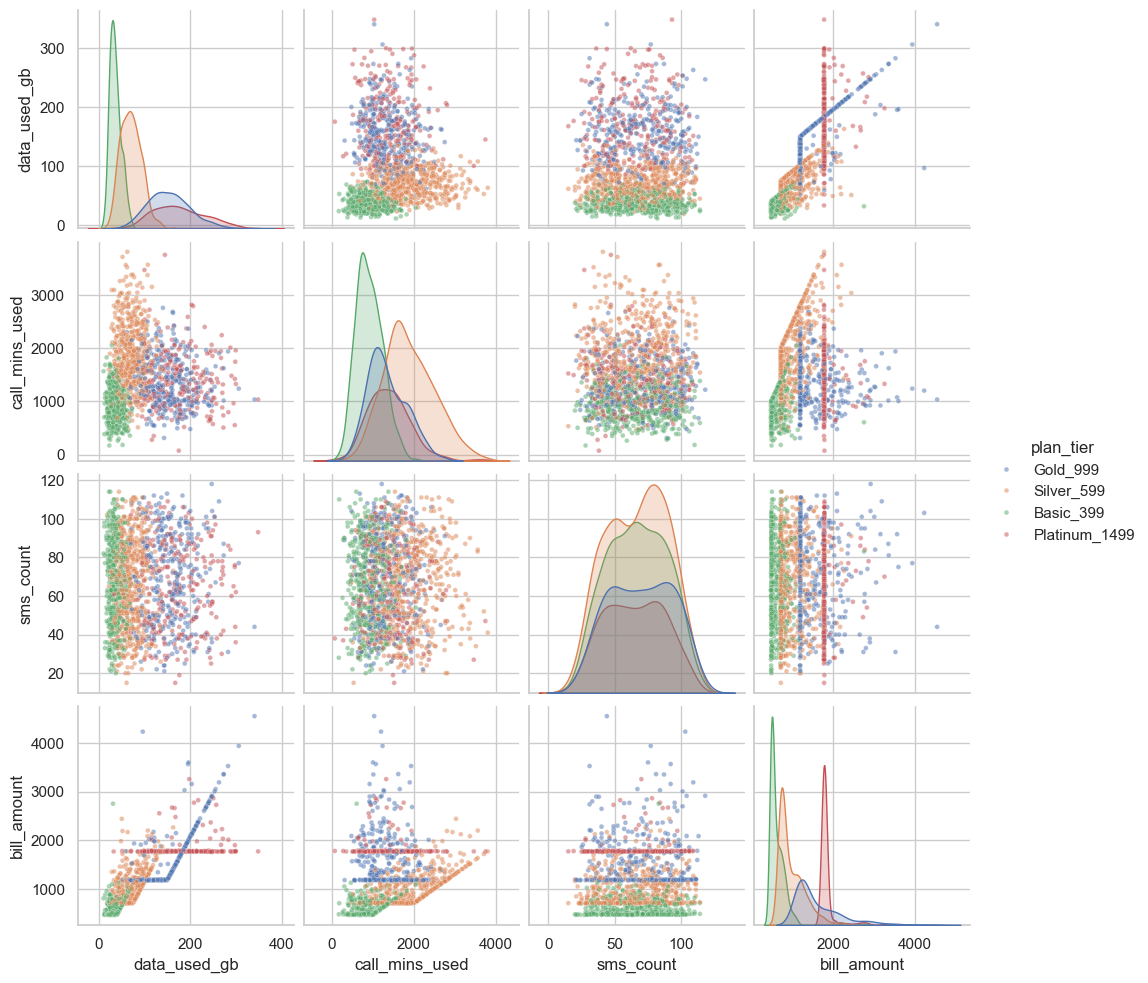

In [32]:
sns.pairplot(df[['data_used_gb', 'call_mins_used', 'sms_count', 'bill_amount', 'plan_tier']],
             hue='plan_tier', plot_kws={'s': 12, 'alpha': 0.5}, height=2.5)
plt.show()

#### Insight
- Data usage and bill amount move together strongly, but the relationship bends upward for heavy users, because overage only applies above each tier's quota.
- Call minutes and SMS count show no clear relationship with the bill.

## 12. Key metrics summary

In [33]:
summary = pd.Series({
    'Customers': df.customer_id.nunique(),
    'Bills (rows)': len(df),
    'Average bill': df.bill_amount.mean(),
    'Median bill': df.bill_amount.median(),
    'Bills with extra-data charges (%)': (df.extra_data_gb > 0).mean() * 100,
    'Bills with ISD charges (%)': ((df.isd_data_gb > 0) | (df.isd_call_min > 0)).mean() * 100,
    'Bills where a cheaper tier exists (%)': (df.potential_saving > 0.5).mean() * 100,
    'Average monthly saving if on cheapest tier': df.potential_saving.mean(),
    'Customers who changed tier': len(switchers),
    'Bill growth, Nov 2025 to Oct 2026 (%)': change['avg_bill'],
})
summary.round(2).to_frame('value')

,value
Customers,125.00
Bills (rows),"1,500.00"
Average bill,"1,132.65"
Median bill,"1,011.15"
Bills with extra-data charges (%),34.20
Bills with ISD charges (%),4.47
Bills where a cheaper tier exists (%),32.20
Average monthly saving if on cheapest tier,109.86
Customers who changed tier,12.00
"Bill growth, Nov 2025 to Oct 2026 (%)",13.40


## 13. Conclusions


1. **Data usage is the main driver of the bill.** Usage has the strongest correlation with the bill (about 0.84), followed by rental (0.76) and extra-data charges (0.54). Average usage is about 36 GB on Basic, 71 GB on Silver, 154 GB on Gold and 176 GB on Platinum, so plans are sized to usage on average. Individual customers still exceed their quota often: about 34% to 51% of bills on capped plans include extra-data charges.
2. **Plan fit is the biggest pricing lever.** About 32% of bills would be cheaper on a different tier for the same usage. The largest gap is on Platinum, where Gold is cheaper in about 55% of bills, because Platinum only beats Gold above roughly 183 GB. Heavy Gold users would pay less on Platinum in about 25% of bills. Potential savings total about 165,000, about 10% of the billed amount.
3. **Bills are rising.** Average bill and data use grew about 13% and 11% over the year, and extra-data charges grew about 60%. Rental prices are fixed in the data, so the increase comes from usage.
4. **Tenure does not predict bills or usage.** Correlations with tenure are near zero, so tenure is not useful for segmenting bill size.
5. **Plan changes are upgrades only.** 12 of 125 customers changed plan, and every change was an upgrade. No customer moved to a cheaper plan, even though many would have paid less on a lower tier.
6. **The largest bills are Gold customers.** Seven of the eight largest bills come from data overage at 195 to 340 GB of usage. The eighth comes from international usage. These are account-level cases to review, not data errors.

**Suggested next steps**
- Offer Platinum customers whose usage is usually below about 180 GB a move to Gold, and offer heavy-usage Gold customers a move to Platinum.
- Target Silver and Basic customers with frequent overage with a plan-change offer.
- Review ISD pricing (250 per GB, 12 per minute) for heavy international users, since it is the most expensive per-unit charge.
- Add a churn label and customer segment fields to the data to test which of these patterns predicts attrition.